# Hybrid Quantum-Classical Neural Networks with PyTorch and Qiskit

**CHEM 584: Introduction to Machine Learning and Quantum Computing**

Prof. Victor S. Batista

*Adapted from the chapter "Hybrid quantum-classical Neural Networks with PyTorch and Qiskit" of the Qiskit Textbook; please check the license terms of the original before redistributing.*

**Version 2.0 · November 2026 · runs on Google Colab with a standard CPU runtime (no GPU needed), Qiskit 2.x and PyTorch.**
**How to cite:** V. S. Batista, *Hybrid quantum-classical neural networks with PyTorch and Qiskit*, CHEM 584 tutorial notebook, version 2.0 (2026).

## 1. Introduction

Machine learning (ML) extracts generalisable information from data, and quantum computing offers new ways to process information. **Quantum machine learning (QML)** explores how the two can help each other: quantum computers might speed up parts of classical ML algorithms, and classical ML tools can be used to optimise quantum algorithms. In this tutorial we build the simplest possible example of the first idea: we take an ordinary neural network and replace one of its layers by a **quantum circuit** that is executed with Qiskit, while PyTorch trains the whole thing. The purpose is to show how easily Qiskit can be integrated with standard ML tools, and, just as important, to examine **honestly what the quantum layer does**.

### What you will learn
After working through this notebook you will be able to:
1. explain what a **parameterised quantum circuit** is and how its measurement statistics can serve as the output of a neural-network layer;
2. derive the output of our one-qubit circuit, $P(1)=\tfrac12(1+\sin\theta)$, and verify it with Qiskit and with a plot that shows **shot noise**;
3. explain the **parameter-shift rule** that makes backpropagation possible through a circuit that we can only sample, and implement it as a custom PyTorch function (with a correct normalisation);
4. train a hybrid CNN to classify handwritten digits (0 versus 1);
5. evaluate it, including the effect of the **number of shots**, and decide whether the quantum layer contributes anything by comparing it with its exact classical equivalent.

### What you need
Basic Python and PyTorch, and an idea of what a qubit and a quantum gate are (a short refresher is given in Section 2). Everything runs on a CPU runtime.

### Roadmap

| Section | Content |
|---|---|
| 2 | Background: neural networks, quantum layers, the parameter-shift rule |
| 3 | Setup: install, settings, imports |
| 4 | The quantum circuit: build, test, shot noise |
| 5 | The quantum layer in PyTorch: forward pass, backward pass, gradient check |
| 6 | Data: MNIST zeros and ones |
| 7 | The hybrid network |
| 8 | Training |
| 9 | Testing, including the effect of the number of shots |
| 10 | Is the quantum layer doing anything? A classical comparison |
| 11 | What now? Exercises, questions, references |

**How to run.** Run the cells from top to bottom. Cells whose code is hidden (form cells) are plumbing or figures; click *Show code* if you are curious.

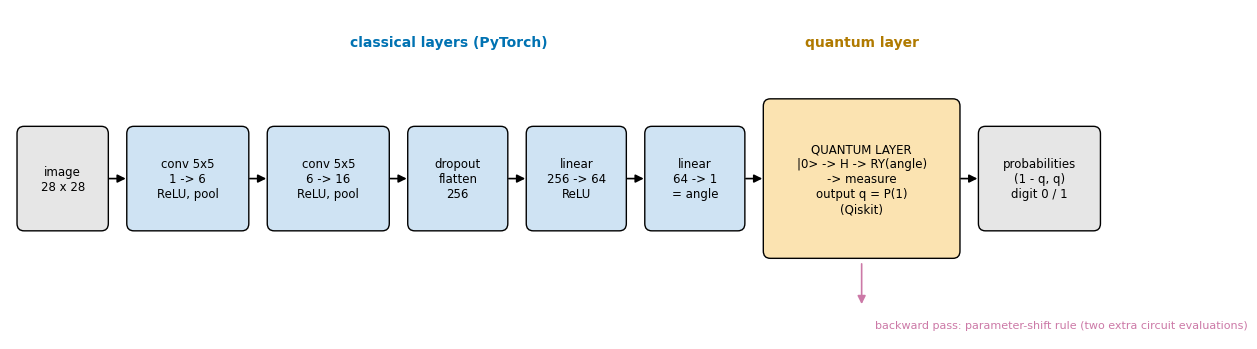

In [1]:
#@title Figure 1: the hybrid network at a glance { display-mode: "form" }
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def box(ax, x, y, w, h, text, fc, fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="k", lw=1))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs)

def arrow(ax, p, q, color="k"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=12, lw=1.2, color=color))

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.set_xlim(0, 13); ax.set_ylim(0, 3.6); ax.axis("off")
blue, orange, gray = "#cfe3f3", "#fbe3b1", "#e6e6e6"
steps = [("image\n28 x 28", gray, 1.0), ("conv 5x5\n1 -> 6\nReLU, pool", blue, 1.35), ("conv 5x5\n6 -> 16\nReLU, pool", blue, 1.35),
         ("dropout\nflatten\n256", blue, 1.1), ("linear\n256 -> 64\nReLU", blue, 1.1), ("linear\n64 -> 1\n= angle", blue, 1.1)]
x = 0.1
for text, col, w in steps:
    box(ax, x, 1.2, w, 1.1, text, col)
    if x > 0.1: arrow(ax, (x - 0.25, 1.75), (x, 1.75))
    x += w + 0.25
qx = x
box(ax, qx, 0.9, 2.2, 1.7, "QUANTUM LAYER\n|0> -> H -> RY(angle)\n-> measure\noutput q = P(1)\n(Qiskit)", orange, 8.5)
arrow(ax, (qx - 0.25, 1.75), (qx, 1.75))
box(ax, qx + 2.45, 1.2, 1.35, 1.1, "probabilities\n(1 - q, q)\ndigit 0 / 1", gray)
arrow(ax, (qx + 2.2, 1.75), (qx + 2.45, 1.75))
ax.text(5.0, 3.2, "classical layers (PyTorch)", ha="center", color="#0072B2", fontsize=10, weight="bold")
ax.text(qx + 1.1, 3.2, "quantum layer", ha="center", color="#b07a00", fontsize=10, weight="bold")
# backward pass
arrow(ax, (qx + 1.1, 0.85), (qx + 1.1, 0.35), color="#CC79A7")
ax.text(qx + 1.25, 0.15, "backward pass: parameter-shift rule (two extra circuit evaluations)", fontsize=8, color="#CC79A7", va="center")
plt.tight_layout(); plt.show()

**Figure 1.** The hybrid network. A small convolutional network (blue, PyTorch) condenses a 28 × 28 image to a **single number**, which is used as the rotation angle of a one-qubit **quantum circuit** (orange, run with Qiskit). The probability $q$ of measuring the qubit in state $|1\rangle$ is the output of the layer, and $(1-q,\,q)$ are the predicted probabilities of the digits 0 and 1. During training, the gradient has to flow backwards through the circuit as well; we obtain it with the parameter-shift rule (Section 2.4).

## 2. Background

### 2.1 A neural network in one paragraph
A neural network is a function built by composing simple building blocks called **neurons**. A neuron takes some numbers, multiplies each by a **weight**, adds them up and applies a simple nonlinear function. We arrange neurons in **layers**: the input is a vector of real numbers, each layer turns the vector it receives into a new vector (its $i$-th component is the output of the $i$-th neuron), and the next layer takes that vector as input. All layers between the first and the last are called **hidden layers**. In a *feed-forward* network the data only flows forward, never back to a neuron that it has already visited. **Training** means choosing the weights such that the network behaves in the desired way, by minimising a **loss** with **gradient descent**, which needs the *gradient* of the loss with respect to every weight (computed by *backpropagation*, the chain rule applied layer by layer). For a short introduction see the video series by 3Blue1Brown.

### 2.2 How can a quantum circuit be a layer?
A layer is any function that maps an input vector to an output vector *and* that we can differentiate. A **parameterised quantum circuit** qualifies: it is a quantum circuit in which the rotation angles of some gates are given by numbers, here the outputs of the previous layer. We run the circuit many times (each run is a *shot*), measure, and collect the **measurement statistics** (for example, the fraction of shots in which a qubit was found in $|1\rangle$). Those numbers are the output of the layer and are the input of the next one (Figure 1).

### 2.3 The circuit used in this tutorial, and what it computes
Our circuit has one qubit and one parameter $\theta$: start in $|0\rangle$, apply a Hadamard gate $H$, then a rotation $R_Y(\theta)$ about the $y$ axis, and measure in the computational basis. Let's calculate the result by hand. After $H$ the state is $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$, and
$$R_Y(\theta)=\begin{pmatrix}\cos\frac\theta2&-\sin\frac\theta2\\ \sin\frac\theta2&\cos\frac\theta2\end{pmatrix}.$$
The amplitude of $|1\rangle$ after the rotation is $(\sin\frac\theta2+\cos\frac\theta2)/\sqrt2$, so the probability of measuring 1 is
$$q(\theta)\;=\;P(1)\;=\;\tfrac12\left(\sin\tfrac\theta2+\cos\tfrac\theta2\right)^2=\tfrac12\,(1+\sin\theta),$$
using $2\sin\frac\theta2\cos\frac\theta2=\sin\theta$. In terms of the Pauli operator $\sigma_z$ (eigenvalues $+1$ for $|0\rangle$ and $-1$ for $|1\rangle$), $\langle\sigma_z\rangle=P(0)-P(1)=-\sin\theta$, hence $q=(1-\langle\sigma_z\rangle)/2$.

> **Take-away.** With one qubit and no entanglement, the "quantum layer" computes the smooth function $q(\theta)=\tfrac12(1+\sin\theta)$, *estimated from a finite number of shots*. We will verify this with Qiskit in Section 4, and use it in Section 10 to ask what the quantum layer really contributes.

### 2.4 What about backpropagation? The parameter-shift rule
To train the network we need $\mathrm{d}q/\mathrm{d}\theta$. On a real quantum computer we cannot inspect the amplitudes; we can only run the circuit and count outcomes. Fortunately, for gates generated by a Pauli operator, such as $R_Y$, there is an **exact** formula that uses only circuit evaluations at shifted angles, the **parameter-shift rule**:
$$\frac{\mathrm{d}q}{\mathrm{d}\theta}\;=\;\frac{q(\theta+s)-q(\theta-s)}{2\sin s},\qquad\text{for example } s=\frac\pi2:\quad \frac{q(\theta+\pi/2)-q(\theta-\pi/2)}{2}.$$
Check it for our circuit: $q(\theta\pm\pi/2)=\tfrac12(1\pm\cos\theta)$, so the difference is $\cos\theta$, and dividing by 2 gives $\tfrac12\cos\theta$, which is exactly $\mathrm{d}q/\mathrm{d}\theta$. This is **not** a finite-difference approximation with a small step: the shift $s=\pi/2$ is macroscopic, and the result is exact. (It is only *noisy*, because every $q$ is estimated from a finite number of shots.) Note the factor $1/(2\sin s)$: the difference $q(\theta+s)-q(\theta-s)$ alone would be **twice** the true gradient here, a point that we test in Section 5.3. With this rule, the circuit becomes a differentiable black box that can be part of a larger backpropagation routine: PyTorch handles the classical layers, and our custom function supplies the gradient of the quantum one.

## 3. Setup

### 3.1 Install Qiskit
Colab already provides PyTorch, torchvision, NumPy and Matplotlib. We add **Qiskit** and `pylatexenc` (which Qiskit needs to draw circuits with Matplotlib). We only use Qiskit's own reference simulator, the `StatevectorSampler` of the *primitives* interface, so no additional simulator package is required.

> **Note on versions.** The 2022 version of this tutorial used `qiskit.Aer`, `assemble` and `backend.run(qobj)`. Those interfaces were removed in Qiskit 1.0. Today a circuit is run through a **primitive**; the `Sampler` returns the measured bit strings and works the same way on simulators and on real hardware.

In [2]:
#@title Install Qiskit { display-mode: "form" }
%pip install -q qiskit pylatexenc

### 3.2 Settings
All the knobs of the tutorial are in one cell. Change a value, then re-run this cell *and everything after it*.

| Setting | Meaning |
|---|---|
| `SEED` | random seed (weights initialisation, data order, shot sampling) |
| `SHOTS` | number of shots per circuit evaluation |
| `EPOCHS` | passes over the training set |
| `LEARNING_RATE` | step size of the Adam optimiser |
| `BATCH_SIZE` | images per gradient step (the quantum layer handles whole batches) |
| `N_TRAIN_PER_CLASS`, `N_TEST_PER_CLASS` | images of each digit in the training and test sets |

In [3]:
#@title Settings { display-mode: "form" }
SEED = 0 #@param {type:"integer"}
SHOTS = 100 #@param {type:"integer"}
EPOCHS = 20 #@param {type:"integer"}
LEARNING_RATE = 1e-3 #@param {type:"number"}
BATCH_SIZE = 1 #@param {type:"integer"}
N_TRAIN_PER_CLASS = 100 #@param {type:"integer"}
N_TEST_PER_CLASS = 50 #@param {type:"integer"}

### 3.3 Imports, seeds and versions

In [4]:
import sys, time, random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.autograd import Function
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.primitives import StatevectorSampler

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

COLORS = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", pink="#CC79A7", gray="#7f7f7f")   # colour-blind safe
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

print(f"python {sys.version.split()[0]} | numpy {np.__version__} | torch {torch.__version__} | qiskit {qiskit.__version__}")

python 3.13.18 | numpy 2.4.6 | torch 2.14.1+cpu | qiskit 2.6.2


## 4. The quantum circuit

### 4.1 Building the circuit
We put the Qiskit parts in a small class. It builds the circuit of Section 2.3 once, with a symbolic parameter $\theta$, and offers a method `run` that takes **a batch of angles**, runs the circuit for each of them with the chosen number of **shots**, and returns, for each angle, the **fraction of shots in which the qubit was measured as 1**. That is the estimate of $q(\theta)$.

How does Qiskit run it? We hand `(circuit, angles)` to a `StatevectorSampler`. For each angle it simulates the circuit exactly and then *draws* `shots` random measurement outcomes, as a real device would produce, and returns them as bit strings; we count the 1s.

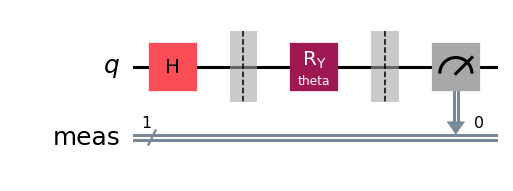

In [5]:
class ParameterizedQubit:
    """One qubit: |0> -> H -> RY(theta) -> measurement.  run(thetas) returns the estimated P(qubit = 1) for each theta."""

    def __init__(self, shots=100, seed=None):
        self.theta = Parameter("theta")
        qc = QuantumCircuit(1)
        qc.h(0)
        qc.barrier()
        qc.ry(self.theta, 0)
        qc.measure_all()                          # adds a classical register called "meas"
        self.circuit = qc
        self.set_shots(shots, seed)

    def set_shots(self, shots, seed=None):
        self.shots = shots
        self.sampler = StatevectorSampler(default_shots=shots, seed=seed)

    def run(self, thetas):
        thetas = np.asarray(thetas, dtype=float).reshape(-1, 1)           # shape (batch, 1): one parameter per circuit
        result = self.sampler.run([(self.circuit, thetas)]).result()[0]   # one "pub" = (circuit, parameter values)
        bits = result.data.meas                                           # the measured bit strings of the "meas" register
        ones = np.array([bits.get_counts(i).get("1", 0) for i in range(len(thetas))])
        return ones / self.shots

qubit = ParameterizedQubit(shots=SHOTS, seed=SEED)
try:                                                                       # a drawing of the circuit
    fig = qubit.circuit.draw("mpl")
    display(fig); plt.close(fig)                                           # (close it, so that it is not shown twice)
except Exception:
    print(qubit.circuit.draw("text"))

### 4.2 Does it do what we computed?
Section 2.3 predicts $q(\theta)=\tfrac12(1+\sin\theta)$. For $\theta=\pi$ this is exactly $0.5$; with a finite number of shots we expect a number *near* $0.5$.

In [6]:
print(f"Estimated P(1) for theta = pi with {SHOTS} shots: {qubit.run([np.pi])[0]:.2f}   (exact value: 0.50)")

Estimated P(1) for theta = pi with 100 shots: 0.56   (exact value: 0.50)


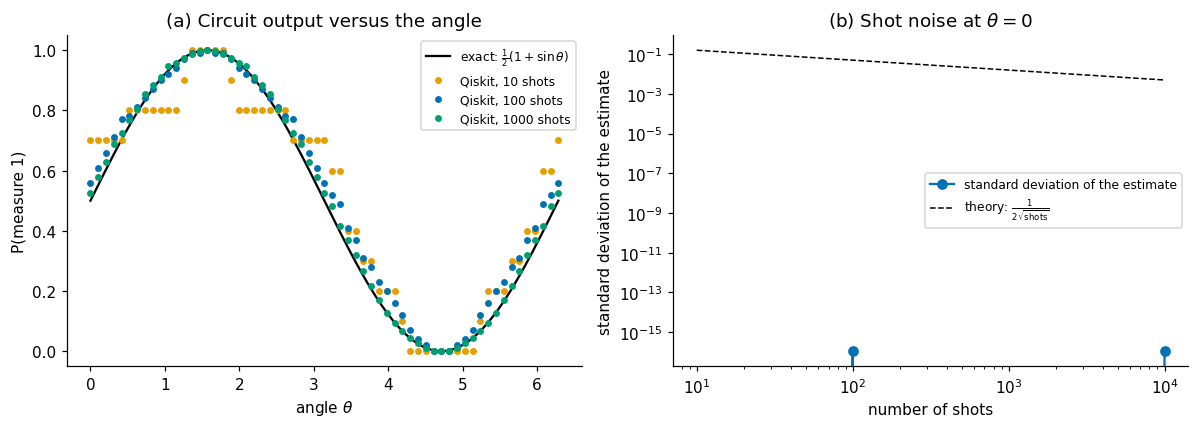

In [7]:
#@title Figure 2: the circuit output and shot noise { display-mode: "form" }
exact = lambda t: 0.5 * (1 + np.sin(t))
thetas = np.linspace(0, 2 * np.pi, 61)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tt = np.linspace(0, 2 * np.pi, 400)
ax[0].plot(tt, exact(tt), "k-", lw=1.5, label=r"exact: $\frac{1}{2}(1+\sin\theta)$")
for shots, col in ((10, COLORS["orange"]), (100, COLORS["blue"]), (1000, COLORS["green"])):
    q = ParameterizedQubit(shots=shots, seed=SEED)
    ax[0].plot(thetas, q.run(thetas), "o", ms=3.5, color=col, label=f"Qiskit, {shots} shots")
ax[0].set(xlabel=r"angle $\theta$", ylabel="P(measure 1)", title="(a) Circuit output versus the angle"); ax[0].legend(fontsize=8)

# shot noise at theta = 0, where P(1) = 1/2 and the noise is largest: repeat the estimate 200 times
shot_values = [10, 100, 1000, 10000]
spread = []
for shots in shot_values:
    q = ParameterizedQubit(shots=shots, seed=SEED)
    spread.append(q.run(np.zeros(200)).std())
ax[1].loglog(shot_values, spread, "o-", color=COLORS["blue"], label="standard deviation of the estimate")
ax[1].loglog(shot_values, 0.5 / np.sqrt(shot_values), "k--", lw=1, label=r"theory: $\frac{1}{2\sqrt{\mathrm{shots}}}$")
ax[1].set(xlabel="number of shots", ylabel="standard deviation of the estimate", title=r"(b) Shot noise at $\theta=0$"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Figure 2.** (a) The estimated probability of measuring 1 for 10, 100 and 1000 shots, against the exact curve $\tfrac12(1+\sin\theta)$ from Section 2.3: the points scatter around the curve, less and less as the number of shots grows. (b) The standard deviation of the estimate at $\theta=0$ (where $P(1)=\tfrac12$ and the noise is largest) shrinks like $1/(2\sqrt{\text{shots}})$, the standard statistical rule: *to halve the noise we need four times as many shots*. On a real quantum computer every shot costs time and money, so the number of shots is a central design parameter of any hybrid algorithm.

## 5. The quantum layer in PyTorch

### 5.1 Forward and backward passes
PyTorch trains networks by *automatic differentiation*: every operation knows how to compute its output (**forward**) and how to turn the gradient with respect to its output into the gradient with respect to its input (**backward**). For our circuit PyTorch has no such knowledge, so we supply it by subclassing `torch.autograd.Function`:

* **forward**: run the circuit for the batch of angles, return the estimated probabilities $q$;
* **backward**: use the parameter-shift rule of Section 2.4. Evaluate the circuit at $\theta+s$ and $\theta-s$ for every angle (in a single call), compute $\mathrm{d}q/\mathrm{d}\theta=[q(\theta+s)-q(\theta-s)]/(2\sin s)$, and multiply by the incoming gradient `grad_output` (the chain rule).

The classes below handle **batches** of images: the circuit is evaluated for all angles of the batch in one call.

In [8]:
class HybridFunction(Function):
    """Hybrid quantum-classical function: forward = run the circuit, backward = parameter-shift rule."""

    @staticmethod
    def forward(ctx, theta, quantum_circuit, shift):
        ctx.shift = shift
        ctx.quantum_circuit = quantum_circuit
        ctx.save_for_backward(theta)
        q = quantum_circuit.run(theta.detach().cpu().numpy())                 # shape (batch,): estimated P(1)
        return torch.as_tensor(q, dtype=theta.dtype, device=theta.device).reshape(-1, 1)

    @staticmethod
    def backward(ctx, grad_output):
        (theta,) = ctx.saved_tensors
        angles = theta.detach().cpu().numpy().reshape(-1)
        both = ctx.quantum_circuit.run(np.concatenate([angles + ctx.shift, angles - ctx.shift]))   # one call: all shifted circuits
        q_right, q_left = both[:len(angles)], both[len(angles):]              # circuit at theta + s, and at theta - s
        dq_dtheta = (q_right - q_left) / (2.0 * np.sin(ctx.shift))            # parameter-shift rule (note the normalisation)
        dq_dtheta = torch.as_tensor(dq_dtheta, dtype=grad_output.dtype, device=grad_output.device).reshape(-1, 1)
        return dq_dtheta * grad_output, None, None                            # chain rule; no gradients for circuit and shift


class Hybrid(nn.Module):
    """Hybrid quantum-classical layer: a (batch, 1) tensor of angles in, a (batch, 1) tensor of P(1) out."""

    def __init__(self, shots=100, shift=np.pi / 2, seed=None):
        super().__init__()
        self.quantum_circuit = ParameterizedQubit(shots, seed)
        self.shift = shift

    def forward(self, theta):
        return HybridFunction.apply(theta, self.quantum_circuit, self.shift)

### 5.2 A word on the loss
The network will output *probabilities* $(1-q,\,q)$ for the digits 0 and 1. The natural loss is the **negative log-likelihood** (NLL): $-\log p_{\text{true class}}$. (PyTorch's `nll_loss` expects the *logarithm* of the probabilities, so we take the logarithm ourselves. The 2022 version of this tutorial fed the raw probabilities to `NLLLoss`, which computes $-p_{\text{true class}}$ and explains the negative loss values near $-1$ in its plots.) A finite number of shots can give an estimate of exactly 0, so we add a tiny constant inside the logarithm to avoid $\log 0$.

### 5.3 Testing the backward pass
A custom gradient is easy to get wrong, so we test it. We use many shots to keep the noise small, and compare three things: the exact derivative $\tfrac12\cos\theta$ (Section 2.4), the parameter-shift estimate with the correct normalisation $1/(2\sin s)$, and the *unnormalised* difference $q(\theta+s)-q(\theta-s)$.

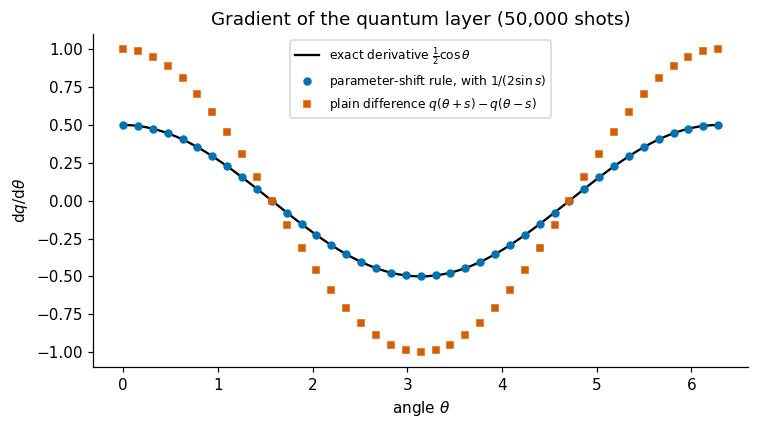

max |parameter-shift - exact|        = 0.0010
max |plain difference / exact - 2|   : the plain difference is 2.00 times the exact derivative


In [9]:
#@title Figure 3: checking the gradient { display-mode: "form" }
check = ParameterizedQubit(shots=50_000, seed=SEED)                            # many shots: small noise
tt = np.linspace(0, 2 * np.pi, 41)
s = np.pi / 2
difference = check.run(tt + s) - check.run(tt - s)                             # q(theta+s) - q(theta-s)
shift_rule = difference / (2 * np.sin(s))                                       # with the normalisation
analytic = 0.5 * np.cos(tt)                                                     # exact derivative of (1 + sin(theta))/2

fig, ax = plt.subplots(figsize=(7, 4))
tf = np.linspace(0, 2 * np.pi, 300)
ax.plot(tf, 0.5 * np.cos(tf), "k-", lw=1.5, label=r"exact derivative $\frac{1}{2}\cos\theta$")
ax.plot(tt, shift_rule, "o", ms=4.5, color=COLORS["blue"], label="parameter-shift rule, with $1/(2\\sin s)$")
ax.plot(tt, difference, "s", ms=4, color=COLORS["red"], label="plain difference $q(\\theta+s)-q(\\theta-s)$")
ax.set(xlabel=r"angle $\theta$", ylabel=r"$\mathrm{d}q/\mathrm{d}\theta$", title="Gradient of the quantum layer (50,000 shots)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"max |parameter-shift - exact|        = {np.abs(shift_rule - analytic).max():.4f}")
print(f"max |plain difference / exact - 2|   : the plain difference is {np.median(difference[np.abs(analytic) > 0.2] / analytic[np.abs(analytic) > 0.2]):.2f} times the exact derivative")

**Figure 3.** The blue points (parameter-shift rule with the factor $1/(2\sin s)$) lie on the exact derivative (black); the red squares (the plain difference) are **twice as large**. Using the unnormalised difference in `backward`, as in the 2022 version of this tutorial, therefore doubles the gradient that flows from the quantum layer into the classical layers. The training may still converge (the Adam optimiser rescales gradients), but the gradient is wrong, and the error would matter in a larger circuit or with a different optimiser.

We also check that the whole `autograd` machinery agrees (it uses the shot-noisy estimates, so we compare with a tolerance):

In [10]:
angles = torch.tensor(np.linspace(0.2, 6.0, 12), dtype=torch.float32).reshape(-1, 1).requires_grad_(True)
layer_check = Hybrid(shots=50_000, seed=SEED)
out = layer_check(angles)
out.sum().backward()                                              # backward pass through the quantum layer
expected = 0.5 * np.cos(angles.detach().numpy())
print("output of the layer     :", np.round(out.detach().numpy().ravel(), 3))
print("exact (1 + sin t)/2     :", np.round(0.5 * (1 + np.sin(angles.detach().numpy().ravel())), 3))
print("max |autograd gradient - exact gradient| =", float(np.abs(angles.grad.numpy() - expected).max()))

output of the layer     : [0.602 0.832 0.975 0.989 0.868 0.655 0.392 0.158 0.022 0.014 0.135 0.363]
exact (1 + sin t)/2     : [0.599 0.832 0.975 0.989 0.87  0.65  0.39  0.159 0.021 0.014 0.138 0.36 ]
max |autograd gradient - exact gradient| = 0.0009394586086273193


## 6. Data

We classify two handwritten digits, **0 and 1**, from the [MNIST](http://yann.lecun.com/exdb/mnist/) data set (28 × 28 grey-scale images, which torchvision downloads automatically). To keep the quantum simulation fast we use a small subset: `N_TRAIN_PER_CLASS` images of each digit for training and `N_TEST_PER_CLASS` for testing. (With the default settings: 200 training images and 100 test images.)

In [11]:
def load_mnist_01(train, n_per_class):
    """The first n_per_class images of the digits 0 and 1: returns the full data set, the chosen indices and a Subset."""
    ds = datasets.MNIST(root="./data", train=train, download=True, transform=transforms.ToTensor())
    t = ds.targets.numpy()
    idx = np.concatenate([np.where(t == 0)[0][:n_per_class], np.where(t == 1)[0][:n_per_class]])
    return ds, idx, Subset(ds, idx)

train_ds, train_idx, train_set = load_mnist_01(True, N_TRAIN_PER_CLASS)
test_ds, test_idx, test_set = load_mnist_01(False, N_TEST_PER_CLASS)
print(f"training images: {len(train_set)}  (class counts {np.bincount(train_ds.targets[train_idx].numpy())})")
print(f"test images    : {len(test_set)}  (class counts {np.bincount(test_ds.targets[test_idx].numpy())})")

def make_loader(subset, batch_size, shuffle, seed=SEED):
    g = torch.Generator().manual_seed(seed)                       # a seeded generator: the same shuffling every time
    return DataLoader(subset, batch_size=batch_size, shuffle=shuffle, generator=g)

test_loader = make_loader(test_set, 50, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 52.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.65MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.0MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.86MB/s]

training images: 200  (class counts [100 100])
test images    : 100  (class counts [50 50])


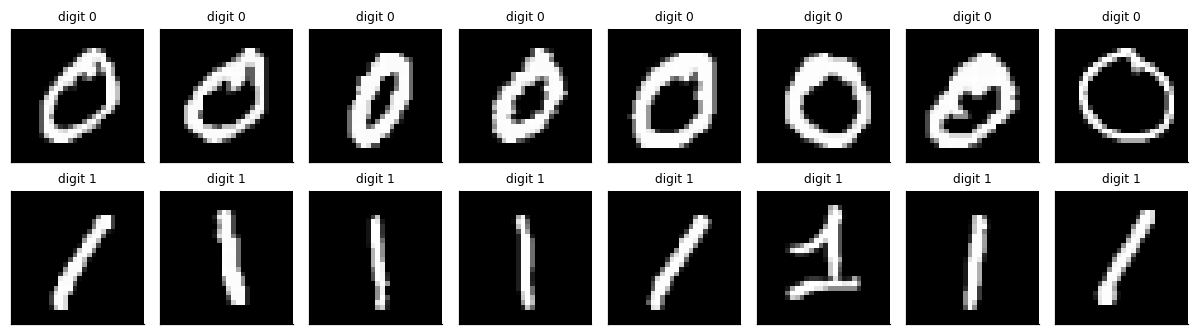

In [12]:
#@title Figure 4: some training images { display-mode: "form" }
fig, axes = plt.subplots(2, 8, figsize=(11, 3.2))
for row, digit in enumerate((0, 1)):
    chosen = [i for i in train_idx if train_ds.targets[i].item() == digit][:8]
    for a, i in zip(axes[row], chosen):
        a.imshow(train_ds.data[i].numpy(), cmap="gray"); a.set_xticks([]); a.set_yticks([]); a.set_title(f"digit {digit}", fontsize=8)
plt.tight_layout(); plt.show()

**Figure 4.** Eight training images of each digit. The two classes look very different, so this is an easy task: ordinary neural networks reach (nearly) perfect accuracy. We use it because it lets us concentrate on the quantum layer.

## 7. The hybrid network

The architecture is shown in Figure 1: two convolutional layers (each followed by ReLU and max-pooling), dropout, two fully connected layers, and the quantum layer. Because our circuit has **one parameter**, the last classical layer must condense the 64 neurons to **one number**, which becomes the angle $\theta$. The output of the quantum layer is $q=P(1)$, and the network returns the probabilities of the two digits $(1-q,\;q)$, so that $q$ is the probability that the image shows a 1.

| Step | Output shape (batch size $B$) |
|---|---|
| input image | $B\times1\times28\times28$ |
| conv 5×5 (1→6), ReLU, max-pool 2 | $B\times6\times12\times12$ |
| conv 5×5 (6→16), ReLU, max-pool 2 | $B\times16\times4\times4$ |
| dropout, flatten | $B\times256$ |
| linear 256→64, ReLU | $B\times64$ |
| linear 64→1: the angle $\theta$ | $B\times1$ |
| **quantum layer**: $q=P(1)$ | $B\times1$ |
| probabilities $(1-q,\,q)$ | $B\times2$ |

The class also accepts `head="exact"`, which replaces the quantum layer by its exact formula $\tfrac12(1+\sin\theta)$, computed classically. We use it in Section 10.

In [13]:
class ExactHead(nn.Module):
    """The exact classical counterpart of the quantum layer of Section 2.3: q = (1 + sin(theta)) / 2, with no shot noise."""
    def forward(self, theta):
        return 0.5 * (1 + torch.sin(theta))


class Net(nn.Module):
    def __init__(self, head="quantum", shots=100, seed=None):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.dropout = nn.Dropout2d()
        self.fc1 = nn.Linear(256, 64)
        self.fc2 = nn.Linear(64, 1)
        self.head = Hybrid(shots, np.pi / 2, seed) if head == "quantum" else ExactHead()

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)         # (B, 6, 12, 12)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)         # (B, 16, 4, 4)
        x = self.dropout(x)
        x = x.flatten(1)                                   # (B, 256)
        x = F.relu(self.fc1(x))                            # (B, 64)
        theta = self.fc2(x)                                # (B, 1): the rotation angle of the circuit
        q = self.head(theta)                               # (B, 1): P(measure 1)
        return torch.cat((1 - q, q), dim=1)                # (B, 2): probabilities of digit 0 and digit 1


set_seed()
model = Net(head="quantum", shots=SHOTS, seed=SEED)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
x_demo, y_demo = next(iter(make_loader(train_set, 4, shuffle=False)))
print(f"trainable (classical) parameters: {n_params:,}")
print("input", tuple(x_demo.shape), "-> output", tuple(model(x_demo).shape), "| rows sum to 1:", bool(torch.allclose(model(x_demo).sum(1), torch.ones(4))))

trainable (classical) parameters: 19,085
input (4, 1, 28, 28) -> output (4, 2) | rows sum to 1: True


## 8. Training

We now have all the ingredients. We use the **Adam** optimiser (learning rate `LEARNING_RATE`), the negative log-likelihood loss of Section 5.2, and train for `EPOCHS` epochs. After every epoch we print the average training loss and the training accuracy (measured on the fly, with dropout active, so slightly pessimistic).

Every training step runs the circuit once in the forward pass and twice in the backward pass (the two shifts), for every image in the batch. With the default settings (batch size 1) this is thousands of small circuit evaluations: be patient, and watch the progress.

In [14]:
EPS = 1e-3          # inside the logarithm: shot noise can give an estimate of exactly 0

def nll(probs, target):
    return F.nll_loss(torch.log(probs + EPS), target)

def train_model(model, train_loader, epochs, lr):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"loss": [], "acc": []}
    t0 = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        loss_sum, correct, n = 0.0, 0, 0
        for data, target in train_loader:
            optimizer.zero_grad()
            probs = model(data)                       # forward pass (runs the circuit)
            loss = nll(probs, target)
            loss.backward()                           # backward pass (parameter-shift rule through the circuit)
            optimizer.step()
            loss_sum += loss.item() * len(target)
            correct += (probs.argmax(1) == target).sum().item()
            n += len(target)
        history["loss"].append(loss_sum / n); history["acc"].append(100 * correct / n)
        print(f"epoch {epoch + 1:2d}/{epochs} | loss {history['loss'][-1]:.4f} | train accuracy {history['acc'][-1]:5.1f}% | {time.perf_counter() - t0:5.0f} s")
    history["time"] = time.perf_counter() - t0
    return history

set_seed()
model = Net(head="quantum", shots=SHOTS, seed=SEED)                 # a fresh model with the seed's initial weights
hist_quantum = train_model(model, make_loader(train_set, BATCH_SIZE, shuffle=True), EPOCHS, LEARNING_RATE)

epoch  1/20 | loss 0.2960 | train accuracy  88.5% |     2 s
epoch  2/20 | loss 0.0993 | train accuracy 100.0% |     4 s
epoch  3/20 | loss 0.1044 | train accuracy  99.5% |     6 s
epoch  4/20 | loss 0.0953 | train accuracy 100.0% |     8 s
epoch  5/20 | loss 0.0855 | train accuracy 100.0% |    10 s
epoch  6/20 | loss 0.0546 | train accuracy 100.0% |    12 s
epoch  7/20 | loss 0.0637 | train accuracy 100.0% |    14 s
epoch  8/20 | loss 0.0527 | train accuracy 100.0% |    16 s
epoch  9/20 | loss 0.0566 | train accuracy 100.0% |    17 s
epoch 10/20 | loss 0.0540 | train accuracy 100.0% |    20 s
epoch 11/20 | loss 0.0400 | train accuracy 100.0% |    23 s
epoch 12/20 | loss 0.0484 | train accuracy 100.0% |    24 s
epoch 13/20 | loss 0.0316 | train accuracy 100.0% |    26 s
epoch 14/20 | loss 0.0273 | train accuracy 100.0% |    28 s
epoch 15/20 | loss 0.0239 | train accuracy 100.0% |    30 s
epoch 16/20 | loss 0.0269 | train accuracy 100.0% |    31 s
epoch 17/20 | loss 0.0158 | train accura

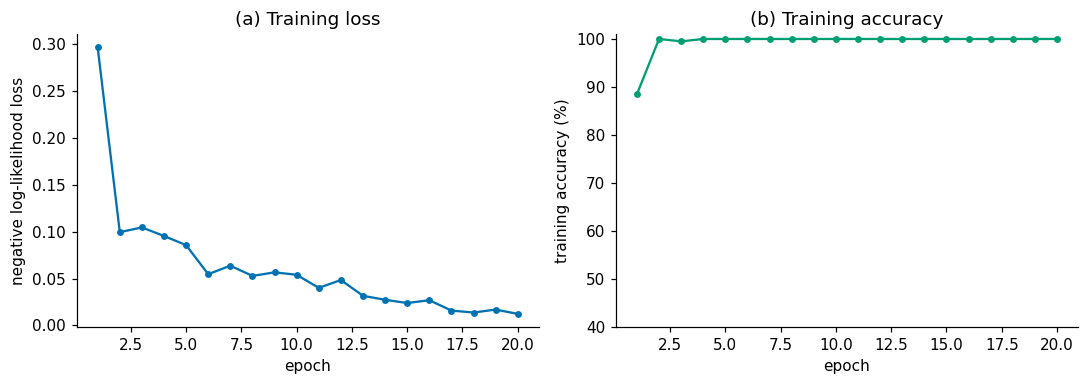

In [15]:
#@title Figure 5: training curves { display-mode: "form" }
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(np.arange(1, EPOCHS + 1), hist_quantum["loss"], "o-", ms=3.5, color=COLORS["blue"])
ax[0].set(xlabel="epoch", ylabel="negative log-likelihood loss", title="(a) Training loss")
ax[1].plot(np.arange(1, EPOCHS + 1), hist_quantum["acc"], "o-", ms=3.5, color=COLORS["green"])
ax[1].set(xlabel="epoch", ylabel="training accuracy (%)", title="(b) Training accuracy", ylim=(40, 101))
plt.tight_layout(); plt.show()

**Figure 5.** Training loss (a) and accuracy (b) of the hybrid network per epoch. A loss that falls toward 0 and an accuracy that rises toward 100 % mean that the whole chain, including the gradient that flows through the quantum circuit via the parameter-shift rule, is working. (The loss is $-\log p$: a loss of 0.1 corresponds to an average probability of about 0.9 for the correct digit.)

## 9. Testing

We evaluate the trained network on test images that it has never seen.

In [16]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    probs_all, targets_all = [], []
    for data, target in loader:
        probs_all.append(model(data)); targets_all.append(target)
    probs, targets = torch.cat(probs_all), torch.cat(targets_all)
    return dict(loss=nll(probs, targets).item(), acc=100 * (probs.argmax(1) == targets).float().mean().item(),
                probs=probs.numpy(), targets=targets.numpy())

res_quantum = evaluate(model, test_loader)
print(f"Performance on {len(test_set)} test images: loss {res_quantum['loss']:.4f}, accuracy {res_quantum['acc']:.1f}%")
confusion = np.zeros((2, 2), dtype=int)
for t, p in zip(res_quantum["targets"], res_quantum["probs"].argmax(1)):
    confusion[t, p] += 1
print("confusion matrix (rows: true digit, columns: predicted digit):\n", confusion)

Performance on 100 test images: loss 0.0233, accuracy 100.0%
confusion matrix (rows: true digit, columns: predicted digit):
 [[50  0]
 [ 0 50]]


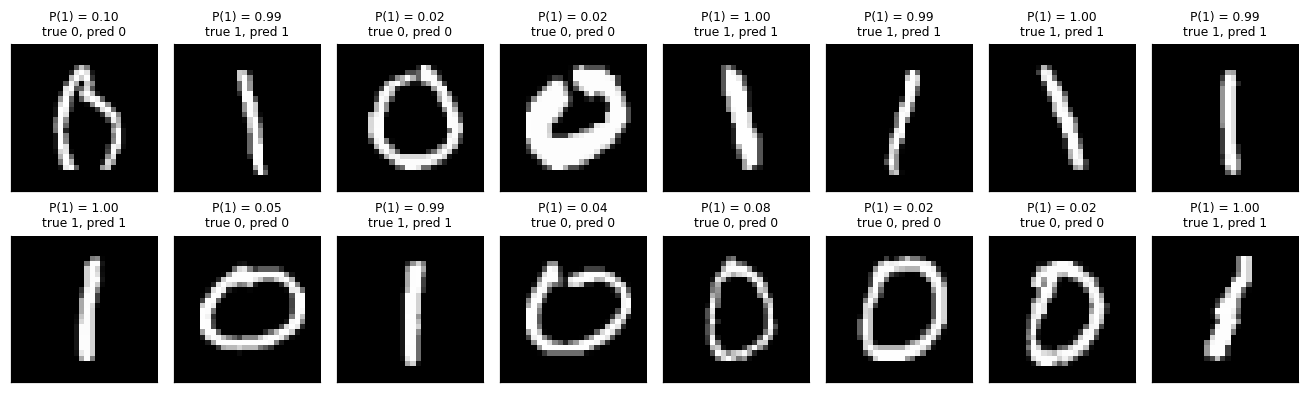

In [17]:
#@title Figure 6: some predictions { display-mode: "form" }
fig, axes = plt.subplots(2, 8, figsize=(12, 3.8))
rng = np.random.default_rng(SEED)
for a, k in zip(axes.ravel(), rng.choice(len(test_set), size=16, replace=False)):
    img, label = test_set[k]
    p1 = res_quantum["probs"][k, 1]
    pred = int(p1 > 0.5)
    a.imshow(img.numpy().squeeze(), cmap="gray"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"P(1) = {p1:.2f}\ntrue {label}, pred {pred}", fontsize=8, color="black" if pred == label else COLORS["red"])
plt.tight_layout(); plt.show()

**Figure 6.** Sixteen random test images with the probability that the network assigns to "digit 1" (the quantum-layer output $q$), the true label and the prediction. Misclassified images, if any, are printed in red.

### 9.1 Does the number of shots matter at test time?
The prediction of the hybrid network is **stochastic**: each time we evaluate it, the circuit gives slightly different numbers. We can change the number of shots *after* training, and ask how much the test performance depends on it. The last row uses the **exact** probability (infinitely many shots, the limit of Figure 2).

In [18]:
rows = []
shot_values = [1, 10, 100, 1000, 10000]
for shots in shot_values:
    model.head.quantum_circuit.set_shots(shots, seed=SEED)
    r = evaluate(model, test_loader)
    rows.append((str(shots), r["acc"], r["loss"], float(np.mean(np.where(r["targets"] == 1, r["probs"][:, 1], r["probs"][:, 0])))))
quantum_head = model.head
model.head = ExactHead()                                             # the exact limit
r = evaluate(model, test_loader); rows.append(("exact", r["acc"], r["loss"], float(np.mean(np.where(r["targets"] == 1, r["probs"][:, 1], r["probs"][:, 0])))))
model.head = quantum_head
model.head.quantum_circuit.set_shots(SHOTS, seed=SEED)               # back to the training setting

print(f"{'shots':>7s} {'accuracy (%)':>13s} {'loss':>8s} {'mean prob. of the true class':>30s}")
for shots, acc, loss, pt in rows:
    print(f"{shots:>7s} {acc:13.1f} {loss:8.3f} {pt:30.3f}")

  shots  accuracy (%)     loss   mean prob. of the true class
      1         100.0   -0.001                          1.000
     10         100.0    0.009                          0.991
    100         100.0    0.023                          0.977
   1000         100.0    0.016                          0.984
  10000         100.0    0.015                          0.985
  exact         100.0    0.015                          0.985


**Table 1.** Test accuracy, loss and the average probability assigned to the correct digit, for different numbers of shots (and for the exact limit). With very few shots each estimate of $q$ is just a handful of coin flips, so we expect the predictions to degrade; with more shots the network should approach its exact limit (last row). Read the numbers of your own run: at which number of shots does the network become indistinguishable from the exact limit? (Training with noisy outputs can also act as a mild regulariser.)

## 10. Is the quantum layer doing anything?

A fair question: does this *quantum* layer give any benefit? We can answer it with an experiment. In Section 2.3 we showed that the layer computes $q(\theta)=\tfrac12(1+\sin\theta)$, estimated with shot noise. The class `ExactHead` computes that same function directly on the classical computer. If we train the **identical** network with the exact head, starting from the same initial weights and seeing the same data in the same order, any difference in performance can only come from the shot noise.

In [19]:
set_seed()
model_exact = Net(head="exact")
hist_exact = train_model(model_exact, make_loader(train_set, BATCH_SIZE, shuffle=True), EPOCHS, LEARNING_RATE)
res_exact = evaluate(model_exact, test_loader)

epoch  1/20 | loss 0.2662 | train accuracy  89.0% |     1 s
epoch  2/20 | loss 0.0744 | train accuracy 100.0% |     1 s
epoch  3/20 | loss 0.0819 | train accuracy 100.0% |     1 s
epoch  4/20 | loss 0.0786 | train accuracy 100.0% |     2 s
epoch  5/20 | loss 0.0648 | train accuracy 100.0% |     3 s
epoch  6/20 | loss 0.0381 | train accuracy 100.0% |     3 s
epoch  7/20 | loss 0.0459 | train accuracy 100.0% |     4 s
epoch  8/20 | loss 0.0357 | train accuracy 100.0% |     5 s
epoch  9/20 | loss 0.0418 | train accuracy 100.0% |     5 s
epoch 10/20 | loss 0.0395 | train accuracy 100.0% |     6 s
epoch 11/20 | loss 0.0238 | train accuracy 100.0% |     6 s
epoch 12/20 | loss 0.0330 | train accuracy 100.0% |     7 s
epoch 13/20 | loss 0.0211 | train accuracy 100.0% |     7 s
epoch 14/20 | loss 0.0161 | train accuracy 100.0% |     8 s
epoch 15/20 | loss 0.0158 | train accuracy 100.0% |     8 s
epoch 16/20 | loss 0.0169 | train accuracy 100.0% |     9 s
epoch 17/20 | loss 0.0102 | train accura

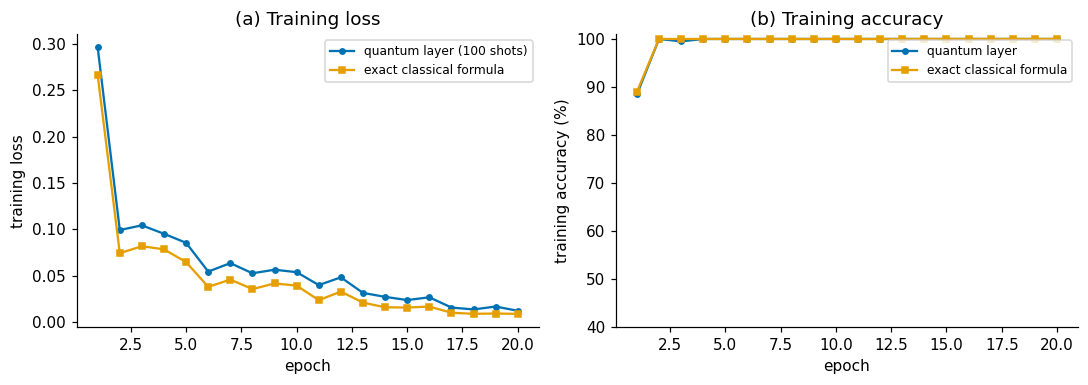

                                  test accuracy (%)  test loss  training time (s)
hybrid, quantum layer                         100.0      0.023                 39
same network, exact formula                   100.0      0.016                 11


In [20]:
#@title Figure 7: quantum layer versus its exact classical counterpart { display-mode: "form" }
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ep = np.arange(1, EPOCHS + 1)
ax[0].plot(ep, hist_quantum["loss"], "o-", ms=3.5, color=COLORS["blue"], label=f"quantum layer ({SHOTS} shots)")
ax[0].plot(ep, hist_exact["loss"], "s-", ms=3.5, color=COLORS["orange"], label="exact classical formula")
ax[0].set(xlabel="epoch", ylabel="training loss", title="(a) Training loss"); ax[0].legend(fontsize=8)
ax[1].plot(ep, hist_quantum["acc"], "o-", ms=3.5, color=COLORS["blue"], label="quantum layer")
ax[1].plot(ep, hist_exact["acc"], "s-", ms=3.5, color=COLORS["orange"], label="exact classical formula")
ax[1].set(xlabel="epoch", ylabel="training accuracy (%)", title="(b) Training accuracy", ylim=(40, 101)); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'':32s} {'test accuracy (%)':>18s} {'test loss':>10s} {'training time (s)':>18s}")
print(f"{'hybrid, quantum layer':32s} {res_quantum['acc']:18.1f} {res_quantum['loss']:10.3f} {hist_quantum['time']:18.0f}")
print(f"{'same network, exact formula':32s} {res_exact['acc']:18.1f} {res_exact['loss']:10.3f} {hist_exact['time']:18.0f}")

**Figure 7 and Table 2.** The two networks have the same architecture, initial weights and data order. Compare their curves, their test performance and, notably, the **training time**: the exact version replaces thousands of circuit simulations by a single line of arithmetic. The original tutorial reported that the classical layers train equally well, or better, without the quantum layer. If your two curves and test results agree as well, that is the honest answer to the question above: in this example the quantum layer contributes **nothing that the formula $\tfrac12(1+\sin\theta)$ does not**, apart from shot noise and a large computational cost. (A single run per model is not a statistical test; Exercise 4 asks you to repeat it for several seeds.)

## 11. What now?

Creating hybrid networks is easy, as this tutorial shows. Whether they are *useful* is the research question:

* Our quantum layer has **one qubit and no entanglement**, so it is trivially simulated on a classical computer (we did exactly that with `ExactHead`), and the classical layers of the network do all the work. The network also trains well without the quantum layer.
* To hope for a quantum advantage one needs a more sophisticated quantum layer: more qubits, entangling gates, data encoded in several rotation angles, perhaps several layers. The software structure stays the same: the circuit is a black box with a forward pass (sample the circuit) and a backward pass (parameter shifts).
* On **real hardware** the same code applies, with a different primitive (the `Sampler` of a hardware provider); the number of shots, the noise of the device and the queue time become the practical constraints. For production use, Qiskit also offers a ready-made connector between circuits and PyTorch in the `qiskit-machine-learning` package.

The point of this exercise was to get you thinking about integrating techniques from machine learning and quantum computing, and to give you a tool for testing ideas: thanks to PyTorch and Qiskit, it is a little easier.

### Check your understanding
1. For the circuit of Section 2.3, show that $P(1)=\tfrac12(1+\sin\theta)$.
2. Why can't we use ordinary backpropagation through the circuit on real quantum hardware, and what do we use instead?
3. What do you expect if you change `SHOTS` from 100 to 400, for the noise of the output and for the training time?
4. Our `backward` divides the difference $q(\theta+s)-q(\theta-s)$ by $2\sin s$. What would happen to the gradient if we did not?
5. Why can the network in this tutorial not show a quantum advantage?

<details><summary>Answers</summary>

1. After $H$ the state is $(|0\rangle+|1\rangle)/\sqrt2$; $R_Y(\theta)$ turns the amplitude of $|1\rangle$ into $(\sin\frac\theta2+\cos\frac\theta2)/\sqrt2$, so $P(1)=\tfrac12(1+2\sin\frac\theta2\cos\frac\theta2)=\tfrac12(1+\sin\theta)$.
2. On hardware we cannot read the amplitudes (or the gradient) of the quantum state, only shot outcomes. We use the parameter-shift rule: two additional circuit evaluations at shifted angles give the exact gradient (with shot noise).
3. The standard deviation of each estimate is halved (it scales as $1/\sqrt{\text{shots}}$), and the number of simulated or executed shots, hence roughly the quantum part of the training time, grows by a factor of four.
4. It would be twice the true gradient for this circuit (Figure 3), and a wrongly scaled gradient flows back into all earlier layers.
5. It has one qubit and no entanglement: the layer computes the simple function $\tfrac12(1+\sin\theta)$, which a classical computer evaluates instantly (Section 10).
</details>

### Exercises
1. **Shots and learning.** Train with `SHOTS` = 10, 100 and 1000. How do the training curves and the test accuracy change? How does the training time change?
2. **Batch size.** Set `BATCH_SIZE` = 1, 8 and 32 (and, if you like, adapt `LEARNING_RATE`). The quantum layer evaluates whole batches in one call. What is the effect on speed and on the final accuracy?
3. **A different circuit.** Replace $R_Y$ by $R_X$, or remove the Hadamard gate. What is the new output function $q(\theta)$? Derive it first, then check it as in Figure 2. Does the parameter-shift rule still hold with the same shift?
4. **Error bars.** Repeat the comparison of Section 10 for five seeds and report the mean and standard deviation of the test accuracy and loss of both networks. Is there a significant difference?
5. **More qubits.** Extend the circuit to two qubits with a CNOT gate, so that the layer has two parameters and two outputs. You will have to change the shape handling in `ParameterizedQubit.run`, `HybridFunction` and `Net`. Is the new layer still easy to simulate classically?
6. **Noise.** Add readout noise (flip each measured bit with probability 5 %) in `ParameterizedQubit.run`. How does the accuracy depend on it, and how would you correct for it?

### Troubleshooting

| Symptom | What to do |
|---|---|
| `ModuleNotFoundError: No module named 'qiskit'` | Run the install cell in Section 3.1, then restart the session if Colab asks you to. |
| `ImportError` for `pylatexenc` when drawing the circuit | The cell falls back to a text drawing; run the install cell to get the picture. |
| The MNIST download fails | Re-run the cell; the data are fetched from mirror servers, and a short outage can occur. |
| Training is slow | Increase `BATCH_SIZE`, lower `EPOCHS` or `SHOTS`, or use fewer images (`N_TRAIN_PER_CLASS`). |
| Results differ slightly from run to run | Shot sampling and dropout are random; the seeds fix them on the same software versions only. |

### References
* Qiskit Textbook, chapter *Hybrid quantum-classical Neural Networks with PyTorch and Qiskit* (the starting point of this tutorial).
* K. Mitarai, M. Negoro, M. Kitagawa, K. Fujii, *Quantum circuit learning*, Phys. Rev. A **98**, 032309 (2018).
* M. Schuld, V. Bergholm, C. Gogolin, J. Izaac, N. Killoran, *Evaluating analytic gradients on quantum hardware*, Phys. Rev. A **99**, 032331 (2019). arXiv:1811.11184
* G. E. Crooks, *Gradients of parameterized quantum gates using the parameter-shift rule and gate decomposition* (2019). arXiv:1905.13311
* A. Javadi-Abhari et al., *Quantum computing with Qiskit* (2024). arXiv:2405.08810
* A. Paszke et al., *PyTorch: an imperative style, high-performance deep learning library*, NeurIPS (2019).
* D. P. Kingma, J. Ba, *Adam: a method for stochastic optimization*, ICLR (2015). arXiv:1412.6980
* Y. LeCun, L. Bottou, Y. Bengio, P. Haffner, *Gradient-based learning applied to document recognition*, Proc. IEEE **86**, 2278–2324 (1998). (MNIST.)